# DDPM Fundamentals：从零生成二维高斯混合分布

**Transformer-to-VLA · Chapter 04 / DDPM Fundamentals**

在圆环 DDPM 的基础上，学习**八模态 Gaussian Mixture**，增加正弦时间嵌入与后验方差采样。这个实验用于直观理解机器人策略中的**多模态动作分布**。

**本节对比上一节**：单环 → 8 个高斯分量；标量时间 → Sinusoidal Time Embedding；简化方差 → DDPM posterior variance。

本 Notebook 可独立运行；请在 Colab CPU / GPU 中从上到下执行所有单元。

## 1. 环境
与圆环 Notebook 一样，无需额外安装 Diffusion 库。

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)


PyTorch: 2.14.1+cu130 | Device: cuda


## 2. 数据集：8 个不同模式

高斯混合分布：

$$
p(\mathbf x_0)=\frac18\sum_{k=1}^8\mathcal N(\mathbf x_0;\boldsymbol\mu_k,0.12^2I).
$$

8 个中心：$(\pm2,0),(0,\pm2),(\pm1.4,\pm1.4)$。每次随机选择一个模式，再加高斯噪声。

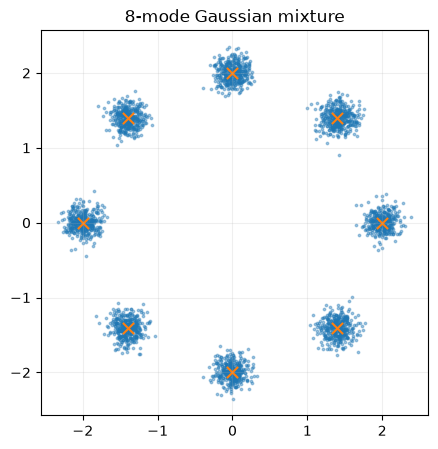

sample shape: torch.Size([32, 2])


In [2]:
CENTERS = torch.tensor([
    [2.0, 0.0], [1.4, 1.4], [0.0, 2.0], [-1.4, 1.4],
    [-2.0, 0.0], [-1.4, -1.4], [0.0, -2.0], [1.4, -1.4],
], device=device)

def sample_data(batch_size, device=device):
    indices = torch.randint(0, len(CENTERS), (batch_size,), device=device)
    return CENTERS[indices] + 0.12 * torch.randn(batch_size, 2, device=device)

real = sample_data(3000).cpu().numpy()
plt.figure(figsize=(5, 5))
plt.scatter(real[:, 0], real[:, 1], s=3, alpha=0.4)
plt.scatter(CENTERS[:, 0].cpu(), CENTERS[:, 1].cpu(), marker="x", s=65)
plt.title("8-mode Gaussian mixture")
plt.axis("equal"); plt.grid(alpha=0.2); plt.show()
print("sample shape:", sample_data(32).shape)

## 3. 前向扩散与后验方差

本实验保留原先的 `T=200` 和线性 $\beta$。

$$
\bar\alpha_t=\prod_{s=1}^{t} (1-\beta_s),\quad
x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon.
$$

用于 reverse sampling 的后验方差是：

$$
\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.
$$

在代码里 `alpha_bar_prev[0]=1` 对应数学定义 $\bar\alpha_0=1$（无噪声的原始数据），所以最后一步方差为 0。

**末端分布检查**：当前短链配置下，$\bar\alpha_T\approx 0.132$，末端仍含原始信号，不能视为已经完全变成标准高斯。采样用 $\mathcal N(0,I)$ 初始化是一项近似，会带来末端分布不匹配。保留此配置用于观察机制；使用相同线性端点并取 `T=1000` 时，$\bar\alpha_T\approx4.04\times10^{-5}$，初始先验更接近前向末端。修改 `T` 后需从噪声调度开始重新运行、训练并比较生成结果。参见 [DDPM 原论文](https://arxiv.org/abs/2006.11239)。


Terminal alpha_bar: 0.132183


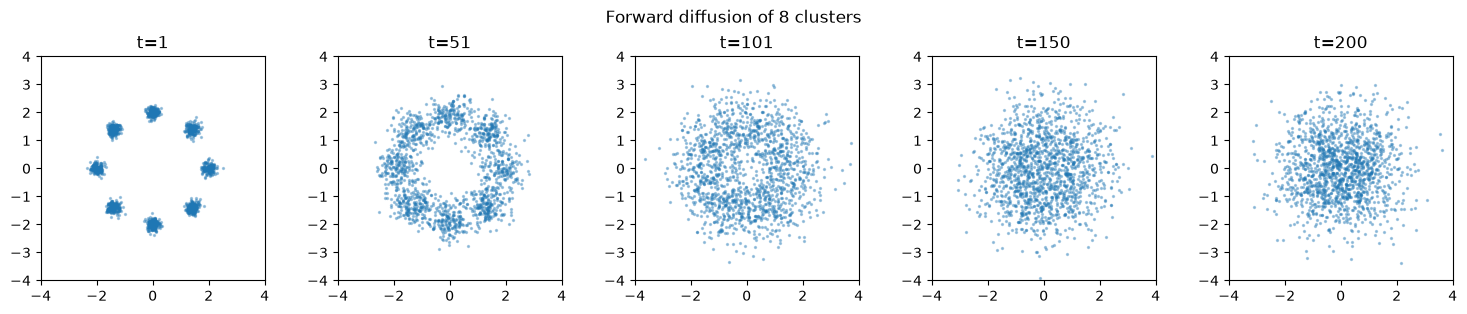

posterior variance at final denoising update (code t=0): 0.0


In [3]:
T = 200
beta = torch.linspace(1e-4, 0.02, T, device=device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)
print(f"Terminal alpha_bar: {alpha_bar[-1].item():.6f}")
alpha_bar_prev = torch.cat([torch.ones(1, device=device), alpha_bar[:-1]])
posterior_variance = beta * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)

def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    return (alpha_bar[t].sqrt().unsqueeze(-1) * x0
            + (1 - alpha_bar[t]).sqrt().unsqueeze(-1) * noise)

x0 = sample_data(1500)
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, step in zip(axes, torch.linspace(0, T - 1, 5).round().long().tolist()):
    t = torch.full((len(x0),), step, device=device, dtype=torch.long)
    xt = q_sample(x0, t).cpu().numpy()
    ax.scatter(xt[:, 0], xt[:, 1], s=2, alpha=0.35)
    ax.set(title=f"t={step+1}", xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
plt.suptitle("Forward diffusion of 8 clusters"); plt.tight_layout(); plt.show()
print("posterior variance at final denoising update (code t=0):", posterior_variance[0].item())

## 4. Sinusoidal Time Embedding

标量 $t$ 本身表达能力有限。我们将时间步映射成多个不同频率的正余弦特征：

$$
\mathrm{TE}(t)=[\sin(t\omega_1),\ldots,\sin(t\omega_m),\cos(t\omega_1),\ldots,\cos(t\omega_m)].
$$

与 Transformer 的正弦位置编码思想相似，但这里编码的是**扩散时间步**，而非 token 的序列位置。

In [4]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        assert dim >= 2 and dim % 2 == 0, "dim must be a positive even integer"
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(
            torch.arange(half, device=t.device, dtype=torch.float32)
            * (-math.log(10000) / max(half - 1, 1))
        )
        angles = t.float().unsqueeze(-1) * freqs.unsqueeze(0)
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=-1)

embedding = SinusoidalTimeEmbedding(32).to(device)
print("embedding shape:", embedding(torch.arange(4, device=device)).shape)

embedding shape: torch.Size([4, 32])


## 5. 噪声预测网络：分别编码点和时间

使用与历史实验一致的基本思路：`x_t → 128`、`TimeEmbedding(32) → 128`，拼接为 256 维，再预测二维噪声。

注意：这里仍是 **MLP DDPM**；不需要为了学习 Diffusion 强行引入 Transformer。

In [5]:
class NoisePredictor(nn.Module):
    def __init__(self, time_dim=32, hidden_dim=128):
        super().__init__()
        self.time_embedding = SinusoidalTimeEmbedding(time_dim)
        self.x_net = nn.Sequential(nn.Linear(2, hidden_dim), nn.SiLU())
        self.t_net = nn.Sequential(nn.Linear(time_dim, hidden_dim), nn.SiLU())
        self.net = nn.Sequential(
            nn.Linear(2 * hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x_t, t):
        x_features = self.x_net(x_t)
        t_features = self.t_net(self.time_embedding(t))
        return self.net(torch.cat([x_features, t_features], dim=-1))

model = NoisePredictor().to(device)
print(model)
print("predicted noise shape:", model(torch.randn(16, 2, device=device),
                                          torch.randint(T, (16,), device=device)).shape)

NoisePredictor(
  (time_embedding): SinusoidalTimeEmbedding()
  (x_net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): SiLU()
  )
  (t_net): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): SiLU()
  )
  (net): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
predicted noise shape: torch.Size([16, 2])


## 6. 训练噪声预测器

与圆环相同的噪声预测 MSE：

$$
\mathcal L=\mathbb E\left[\|\epsilon_\theta(x_t,t)-\epsilon\|^2\right].
$$

原始练习使用 `20,000` 步、`batch_size=512`。为了让 Colab CPU 更易试运行，默认 4,000 步；你可以在 GPU 上改成 20,000 观察生成质量。

step   800/4000 | loss 0.5089


step  1600/4000 | loss 0.4745


step  2400/4000 | loss 0.4533


step  3200/4000 | loss 0.4894


step  4000/4000 | loss 0.4731


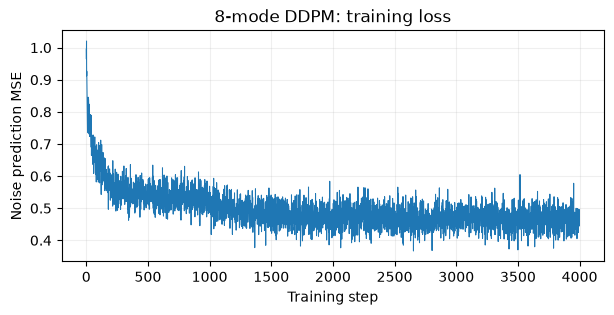

In [6]:
TRAIN_STEPS = 4000        # 更接近历史实验可改为 20000；CPU 快速体验可选 1000
BATCH_SIZE = 512
LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_history = []
model.train()
for step in range(TRAIN_STEPS):
    x0 = sample_data(BATCH_SIZE)
    t = torch.randint(T, (BATCH_SIZE,), device=device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    loss = torch.nn.functional.mse_loss(model(xt, t), noise)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (step + 1) % max(1, TRAIN_STEPS // 5) == 0:
        print(f"step {step + 1:5d}/{TRAIN_STEPS} | loss {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(loss_history, lw=0.75)
plt.title("8-mode DDPM: training loss")
plt.xlabel("Training step"); plt.ylabel("Noise prediction MSE")
plt.grid(alpha=0.2); plt.show()

## 7. Reverse DDPM Sampling

采样均值与圆环练习相同：

$$
\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).
$$

不同之处是使用 $\tilde\beta_t$ 作为采样方差。最后一步采用均值，不再叠加噪声。

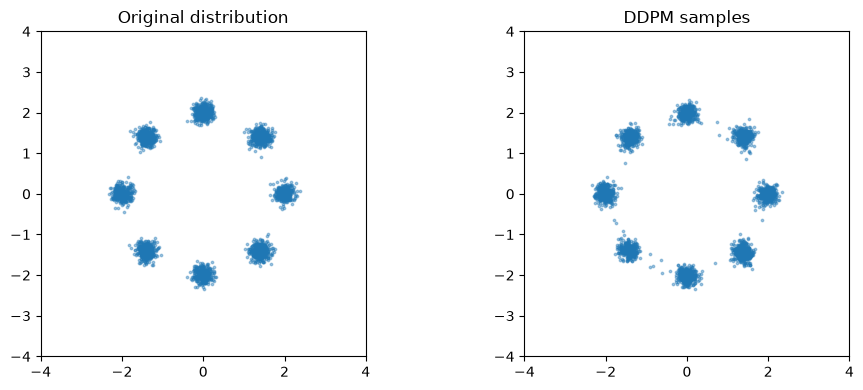

In [7]:
@torch.no_grad()
def sample_ddpm(n_samples=3000, capture_steps=None):
    model.eval()
    if capture_steps is None:
        capture_steps = {round((T - 1) * f) for f in (1, .8, .6, .4, .2, 0)}
    x = torch.randn(n_samples, 2, device=device)
    snapshots = {"initial noise": x.cpu().numpy().copy()}
    for step in reversed(range(T)):
        t = torch.full((n_samples,), step, device=device, dtype=torch.long)
        noise_hat = model(x, t)
        mean = (x - beta[step] / (1 - alpha_bar[step]).sqrt() * noise_hat) / alpha[step].sqrt()
        if step > 0:
            x = mean + posterior_variance[step].sqrt() * torch.randn_like(x)
        else:
            x = mean
        if step in capture_steps:
            snapshots[f"t={step}"] = x.cpu().numpy().copy()
    return x.cpu().numpy(), snapshots

generated, snapshots = sample_ddpm()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, points, title in zip(axes, [real, generated], ["Original distribution", "DDPM samples"]):
    ax.scatter(points[:, 0], points[:, 1], s=3, alpha=0.4)
    ax.set(title=title, xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
plt.tight_layout(); plt.show()

## 8. 可视化模式逐步出现的过程

观察各个高斯簇何时分离。**模型不是逐簇生成点，而是联合学习了一个多峰概率分布。**

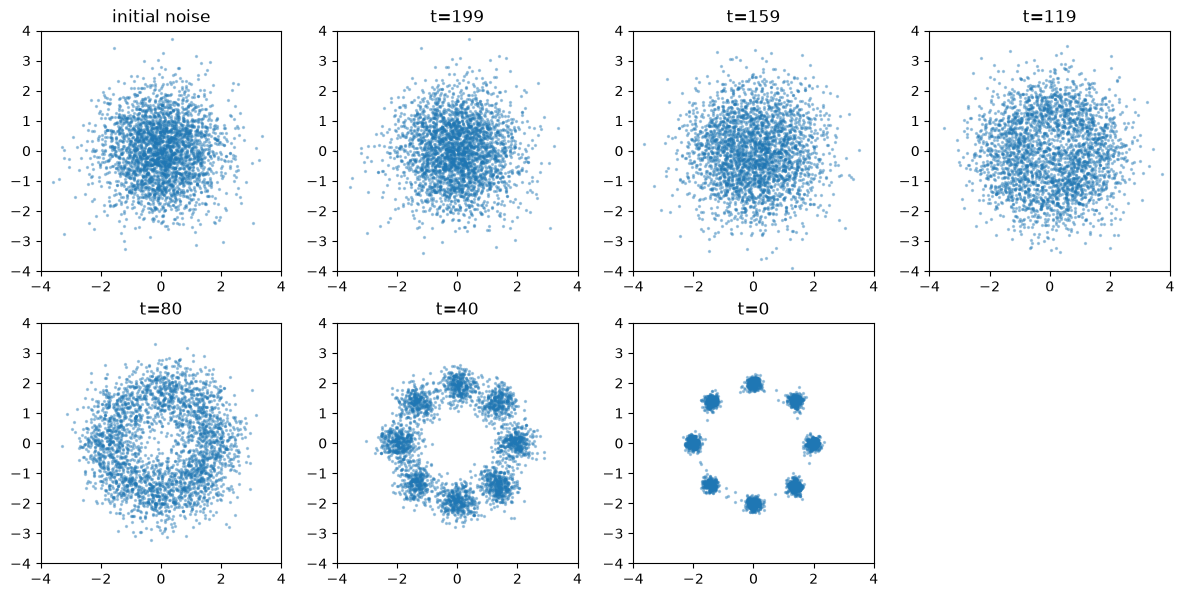

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (label, points) in zip(axes.flat, snapshots.items()):
    ax.scatter(points[:, 0], points[:, 1], s=2, alpha=0.35)
    ax.set(title=label, xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
for ax in axes.flat[len(snapshots):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 9. 动手实验与机器人相关思考

1. 将簇数改为 2 / 4 / 8，观察多峰分布的表达能力。
2. 将簇内标准差从 `0.12` 改为 `0.3`，比较各模式的可辨识程度。
3. 试着替换成圆环实验里的单标量时间输入，观察表达能力与训练稳定性。
4. 对比 posterior variance 与圆环实验中的 `beta[t]`；它们都是可选的 DDPM 反向方差参数化，并不代表所有生成模型都必须使用其中一种。

### 与 Diffusion Policy 的联系

机器人面对障碍物，可能有左绕与右绕两种合理动作方案。**多峰分布学习**提供了生成多种合理候选的基础。但二维数据集中的点还不是机器人轨迹；下一阶段需要把样本变为 $A=[a_t,\ldots,a_{t+H-1}]$，并将观测与目标加入条件。